# 用户行为分析


## 我们要做什么？


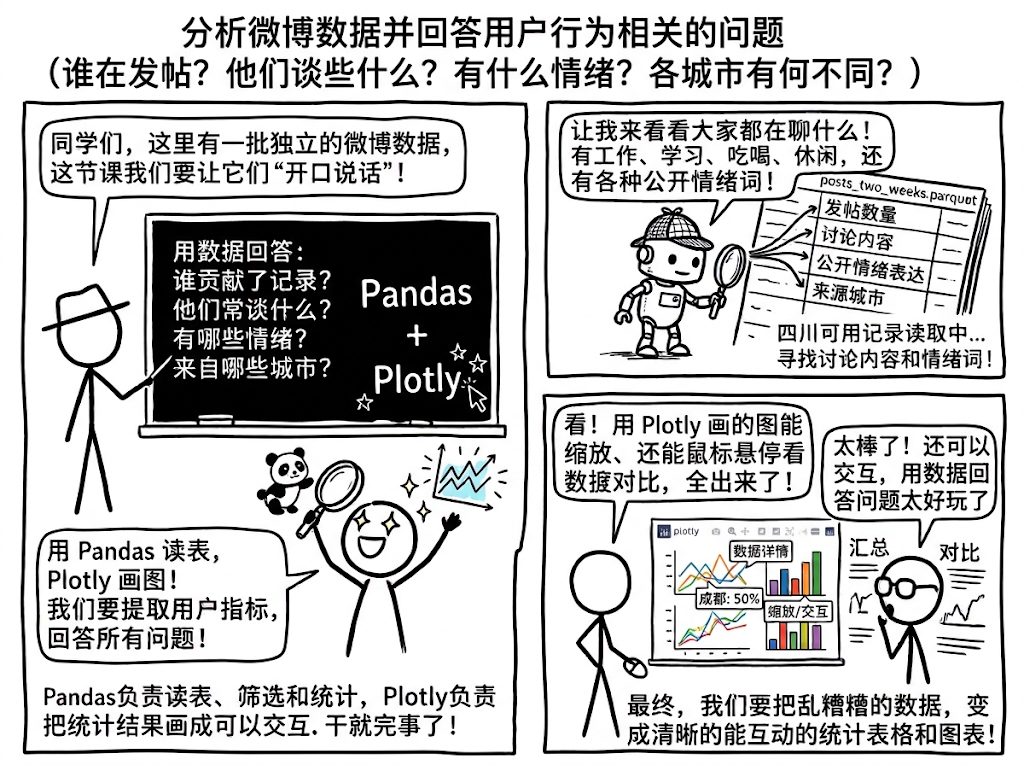

## 用到的数据

`tutorials/data/posts_two_weeks.parquet`

是2022年8月12日到8月25日全国含地理坐标微博数据，我们将重点关注四川省相关的用户行为。该数据不是平台全部发帖，也不是完整用户历史。

让我们开始吧

<a id="section-1"></a>

<!-- course-toc:start -->
<a id="course-toc"></a>
**目录**

- [1 分析哪些行为？](#section-1) **[重点]**
- [2 数据能告诉我们什么？](#section-2)
  - [2.1 环境和真实输入](#section-2-1) **[重点]**
  - [2.2 能不能分析转发、@提及或点赞？先查字段](#section-2-2) **[重点]**
- [3 哪些用户贡献了记录？](#section-3) **[重点]**
  - [3.1 从帖子表变成用户表](#section-3-1) **[重点]**
  - [3.2 均值和中位数分别回答什么？](#section-3-2)
  - [3.3 用户占比和记录贡献占比的分母不同](#section-3-3) **[重点]**
- [4 用户更常谈哪些内容？](#section-4) **[重点]**
  - [4.1 把内容问题变成可复核的关键词规则](#section-4-1) **[重点]**
  - [4.2 同一词表，帖子等权与用户等权](#section-4-2) **[重点]**
  - [4.3 为观察用户内容结构，明确记录门槛](#section-4-3) **[重点]**
- [5 公开表达中的情绪词](#section-5) **[重点]**
  - [5.1 四类可解释规则](#section-5-1)
  - [5.2 回到文本，看看规则命中了什么](#section-5-2) **[重点]**
  - [5.3 文件里的源模型标签怎样使用？](#section-5-3) **[拓展]**
- [6 城市汇总：数量与每用户记录数](#section-6) **[重点]**
- [7 开放问题](#section-7) **[练习]**
  - [7.1 开放问题：怎样定义“记录较多的用户”？](#section-7-1) **[练习]**
  - [7.2 开放问题：“更常谈饮食”会不会只是词表定义的结果？](#section-7-2) **[练习]**
  - [7.3 开放问题：怎样定义“负向表达更多”？](#section-7-3) **[练习]**
  - [7.4 选做：用BERTopic发现讨论主题](#section-7-4) **[拓展]**
  - [7.5 选做：用预训练模型识别文本情感倾向](#section-7-5) **[拓展]**
- [8 分析流程](#section-8)
<!-- course-toc:end -->

<a id="data"></a>
<a id="section-2"></a>
## 2 数据能告诉我们什么？

<a id="section-2-1"></a>
### 2.1 环境和真实输入 **[重点]**

在 VS Code 打开整个项目，选择课程 Python 内核（Conda 或 venv）。本教程独立初始化，
不依赖其他 Notebook 的变量，只用现有 Pandas、Plotly与PyArrow 依赖。
输出表格与图显示在 Notebook 中。



**运行顺序与路径：** 从上到下运行。这里先确定输入文件，后续在第一次用到时导入库、定义参数和创建输出目录。`Path`按当前系统处理路径；`TUTORIAL_DIR`指向课程的`tutorials`文件夹，无需填写Mac或Windows的绝对路径。

**表格展示：** 单元格最后一行直接写`table`或`table.head()`即可显示；同格需要多张表、或在`if`、循环中展示时，再使用`display(...)`。

In [ ]:
# 开始读表时需要Pandas；其他库在相关分析步骤中再导入。
from pathlib import Path
import pandas as pd

In [ ]:
# 查看Parquet字段和元数据时导入PyArrow。
import pyarrow.parquet as pq
# 同一格展示多张表或在分支中显示结果时使用display。
from IPython.display import display

# 根据数据所在位置选择相对目录，兼容从 tutorials 或项目根目录启动。
TUTORIAL_DIR = Path('.') if Path('data/posts_two_weeks.parquet').is_file() else Path('tutorials')
# 拼接同一份两周 Parquet 的输入路径，后面的分析都使用它。
DATA = TUTORIAL_DIR / 'data/posts_two_weeks.parquet'
# 确认输入文件存在；路径不正确时先修正启动目录或补齐课堂数据。
assert DATA.is_file(), '请从 tutorials 或项目根目录启动内核，并保留 tutorials/data'
# 只读取 Parquet 模式中的字段名，用于检查文件是否真的包含互动指标。
source_columns = pq.ParquetFile(DATA).schema_arrow.names
# 按 columns 只读取需要的字段，filters 只保留四川可用记录；得到 Pandas DataFrame。
raw = pd.read_parquet(DATA,
    columns=['post_id', 'user_id', 'date', 'city', 'text',  # 只读取列清单中的字段，减少不必要的读取和内存占用。
             'sentiment_label_source', 'score_valid'],
    filters=[('province_code', '==', '51'), ('usable_text', '==', True)])  # 过滤条件为四川省编码 51 且文本可用；同一组条件按“并且”组合。
# 复制读入的表；后面新增列写入 posts，不修改 raw。
posts = raw.copy()

# 打印计算结果，核对数量、分母、阈值或运行状态。
print('帖子记录数：', len(posts), '不同用户数：', posts['user_id'].nunique(),
      '出现日期数：', posts['date'].nunique())
# shape返回(行数, 列数)，用来确认读入表的规模。
print('表格形状（行、列）：', posts.shape)
# dtypes展示字段类型；ID和日期字符串不应因为外观像数字就参与加减。
display(posts[['user_id', 'date', 'city']].dtypes.to_frame('列类型'))
# 两层方括号取多列，head(3)只预览，不改变posts。
posts[['date', 'city', 'text']].head(3)

**怎么看结果：** 默认范围有 54,609 条可用记录、36,463 个匿名用户，窗口为 2022-08-12 至 08-25。
`post_id` 是帖子主键，`user_id` 用于把同一用户的记录组合起来。
用户不是逐行独立的：同一个人的多条帖子可能相关，不能在统计推断时直接当成独立样本。

<a id="section-2-2"></a>
### 2.2 能不能分析转发、@提及或点赞？先查字段 **[重点]**

一个平台可能支持很多行为，但一个数据文件不一定保留这些行为的字段。
本文件没有独立的原创/转发标记、转发父帖 ID、被提及账号列表或互动数量。
文本来自预处理的 `text_clean`，随后又做了脱敏；即使某个文本模式看不见，也不能断言原帖没有对应行为。

In [ ]:
# 列出常见的转发、提及、点赞和评论字段，随后检查是否存在；不会补造这些指标。
interaction_fields = ['is_repost', 'retweeted_status_id', 'mention_ids',
                       'reposts_count', 'likes_count', 'comments_count']
# 列表推导逐个检查字段是否存在，形成“字段名—存在与否”的审计表。
field_audit = pd.DataFrame({
    '示意字段名': interaction_fields,
    '当前文件是否存在': [name in source_columns for name in interaction_fields],
})
# 在 Notebook 输出区显示本步的结果表。
display(field_audit)
# 统计正文中可见字符或字面词的出现次数；这不等于结构化的提及或转发次数。
text_audit = pd.Series({
    '正文含 @ 字符的记录数': posts['text'].str.contains('@', regex=False, na=False).sum(),
    '正文含 [提及] 掩码的记录数': posts['text'].str.contains('[提及]', regex=False, na=False).sum(),
    '正文含“转发”一词的记录数': posts['text'].str.contains('转发', regex=False, na=False).sum(),
}, name='可见文本计数')
# 最后一行的表格表达式由Notebook自动展示。
text_audit.to_frame()

**怎么看结果：** 本范围里没有可见的 `@` 或 `[提及]`；有 21 条正文包含“转发”一词。
**21 不是转发帖数，0 也不是用户从未提及别人。**
提到“转发”可以是在讨论这个动作，不能替代平台转发元数据。
将来有可验证的动作类型、被提及账号 ID 和转发父帖 ID，才适合分析这些互动或关系。
本教程因此把记录统一称为“帖子记录”，不把它们全部判为原创，也不估计传播影响力。
字段说明见项目 `tutorials/data/README.md`，脱敏过程见 `scripts/prepare_two_weeks.py`。

<a id="activity"></a>
<a id="section-3"></a>
## 3 哪些用户贡献了记录？ **[重点]**

<a id="section-3-1"></a>
### 3.1 从帖子表变成用户表 **[重点]**

先定义指标，再选聚合方式。每个用户一行可以方便地比较用户之间的差异。

| 字段 | 定义 | 分析单位 |
|---|---|---|
| `n_posts` | 该用户在窗口内的采集记录数 | 用户 |
| `observed_days` | 有采集记录的不同日期数 | 用户 |
| `observed_day_share` | 观测日期数 / 14 个日历日 | 用户 |
| `mean_text_length` | 该用户已采集正文的平均字符数 | 用户 |

`observed_day_share` 描述窗口内观测到的发帖日期覆盖，不等于每天使用微博的概率。
字符数也不是词数。没有采集记录的日期，不能直接解释为用户没有使用微博。

In [ ]:
# 这里开始计算用户出现日期占比；观察窗口为两周。
WINDOW_DAYS = 14

# str.len() 逐条计算正文字符数；中文字符计为字符，不是词数或字节数。
posts['text_length'] = posts['text'].str.len()
# 按用户 ID 聚合成一人一行，统计记录数、不同发帖日期数和平均正文长度。
users = posts.groupby('user_id').agg(
    n_posts=('post_id', 'size'),  # size 统计组内行数，不是不同用户数。
    observed_days=('date', 'nunique'),  # 统计出现过记录的不同日期数。
    mean_text_length=('text_length', 'mean'),  # 求组内记录正文长度的平均值。
)
# 用出现过记录的日期数除以 14 天；它描述采集窗口内的观测，不是完整活跃率。
users['observed_day_share'] = users['observed_days'] / WINDOW_DAYS
# 显示结果的前几行，观察索引、列名和数值；head 不改变完整统计结果。
display(users.head(3))
# describe() 给出计数、均值、标准差和分位数，帮助检查指标分布。
# 打印计算结果，核对数量、分母、阈值或运行状态。
print('用户表累计记录数：', users['n_posts'].sum(), '原帖子表记录数：', len(posts))
# 最后一行直接展示表格。
users[['n_posts', 'observed_days', 'mean_text_length']].describe()

<a id="section-3-2"></a>
### 3.2 均值和中位数分别回答什么？

均值反映所有用户的记录总量除以人数；中位数反映排序后处于中间位置的用户。
若少数用户有很多记录，均值可能大于多数用户的记录数。
先看分位数和记录数分布，再决定怎样描述“典型用户”。

In [ ]:
# 汇总用户记录数的均值、中位数、分位数与最大值，用来观察偏态与长尾。
summary = pd.Series({
    '用户数': len(users),
    '每用户平均记录数': users['n_posts'].mean(),
    '每用户记录数中位数': users['n_posts'].median(),
    '记录数75%分位数': users['n_posts'].quantile(0.75),
    '记录数95%分位数': users['n_posts'].quantile(0.95),
    '最大记录数': users['n_posts'].max(),
}, name='统计值')
# 将 Series 转成单列表格并显示，便于一起查看行标签与统计值。
display(summary.to_frame())
# 最后一行的表格表达式由Notebook自动展示。
users['n_posts'].value_counts().sort_index().head(8).rename('用户数').to_frame()

**用直方图查看记录数分布。** 用户表中每行是一位用户，横轴是该用户被采集到的记录数，纵轴是落入相应区间的用户人数。
`px.histogram`会先分箱，再统计人数；这里每个区间宽1，边界设在0.5、1.5、2.5……，使整数记录数位于柱子的中心。

保留全部已观测用户，不截去记录较多的尾部。由于人数相差较大，`log_y=True`将纵轴设为对数刻度：相同距离表示相同倍数，柱高仍对应用户人数；空区间的0人数无法在对数轴上显示。
将它改成`log_y=False`可以观察普通刻度下的分布。两种刻度使用同一批用户，不改变统计结果。

`update_traces(xbins=...)`设置精确分箱；`size=1`是区间宽度，不能用“分成若干箱”的`nbins`代替。

In [ ]:
# 现在绘制交互图：Plotly Express用表格列名指定图形。
import plotly.express as px
import plotly.io as pio
# 同时兼容VS Code显示和离线HTML导出。
pio.renderers.default = 'plotly_mimetype+notebook'
px.defaults.template = 'simple_white'

# 每行是一位用户；默认histfunc='count'，统计落入每个区间的用户人数。
fig = px.histogram(users, x='n_posts', log_y=True,
                   labels={'n_posts': '每位用户的采集记录数'},
                   title='每位用户的采集记录数分布')
# 区间宽度为1，边界从0.5开始；最大记录数也被完整纳入，整数位于柱子中心。
fig.update_traces(xbins=dict(start=0.5, end=users['n_posts'].max() + 0.5, size=1))
# 纵轴显示用户人数；对数刻度有助于观察人数较少的尾部。
fig.update_yaxes(title_text='用户人数（对数刻度）')
# 将交互图直接显示在Notebook中；可悬停查看区间与人数，也可框选缩放。
fig.show()

**怎样读这张图：** 左侧人数最多，右侧延伸出较长的尾部，说明多数用户记录较少，少数用户记录较多。
这也解释了为什么均值会高于中位数。表中最大记录数为155，不能只看中位数而忽略尾部。
本图只包含至少有一条采集记录的用户，无法显示没有被采集到记录的用户。

**直方图与下一张柱形图回答不同的问题：** 本图查看数值分布，每位用户计一次；3.3将记录数划成四个类别，分别计算人数占比和记录贡献占比。
“5条及以上”是一个汇总类别，因此用等宽的分类柱展示，不把它当作宽度为1的数值区间。

**怎么看结果：** 当前窗口中多数用户只被观测到一条帖子，记录数中位数为 1。
这描述样本的稀疏程度，不能据此把他们称为平台上的“低活跃用户”。

<a id="section-3-3"></a>
### 3.3 用户占比和记录贡献占比的分母不同 **[重点]**

将用户按采集记录数划为互斥组：1 条、2 条、3–4 条、5 条及以上。
一种比例数人，另一种比例数帖；两者都要报告。

<details><summary>扩展：能否用直方图同时比较用户与帖子？</summary><p>可以。假设甲有3条帖子、乙有1条，用户表中的记录数为<code>[3, 1]</code>，每人计一次；将用户记录数映射回帖子表，得到<code>[3, 3, 3, 1]</code>，每条帖子计一次。两者可使用相同分箱画在同一张图中。Plotly的<code>histnorm='probability'</code>将每组计数除以相应总数，得到各组占比；<code>histnorm='probability density'</code>还要除以区间宽度，不能直接当作各组占比。也可在用户表中指定<code>y='n_posts', histfunc='sum'</code>汇总每个区间的帖子贡献。这里用并列柱形图展示四个类别，使两种分母更容易比较。</p></details>

**Plotly Express：先得到统计表，再指定横轴和纵轴。** `px.bar`绘制柱形图，`x`指定横轴列，`y`可以是一个列名或多个列名。
这里用`reset_index()`把分组索引变成普通列；`barmode='group'`让两种占比并列显示。
`text_auto='.1%'`在柱上显示百分比，`update_yaxes(tickformat='.0%')`设置纵轴刻度，二者都不改变统计数值。
`fig`是图形对象，`fig.show()`将它显示在Notebook中。悬停查看数值，点击图例切换系列，双击图内空白处恢复缩放。
图例中的两种比例分母不同，要先明确统计口径再解释柱高。

In [ ]:
# NumPy用于本步骤的数值计算。
import numpy as np

# cut 默认右闭区间：1、2、3–4、5+；np.inf 让最后一组包含所有更大的记录数。
groups = pd.cut(users['n_posts'], bins=[0, 1, 2, 4, np.inf],
                labels=['1', '2', '3–4', '5+'])  # 为每个记录数区间指定显示名称。
# 按记录数组统计人数与记录贡献；observed=False 保留没有用户的分类组。
group_summary = users.assign(record_group=groups).groupby(
    'record_group', observed=False).agg(n_users=('n_posts', 'size'), n_posts=('n_posts', 'sum'))
# 人数除以全体已观测用户数；分母的单位是用户。
# 重点：用户占比的分母是全部已观测用户数 len(users)，统计单位是用户。
group_summary['user_share'] = group_summary['n_users'] / len(users)
# 组内用户的记录总数除以全体帖子记录数；分母的单位是帖子。
# 重点：记录贡献占比的分母是全部帖子数 len(posts)，不能沿用用户比例的分母。
group_summary['post_share'] = group_summary['n_posts'] / len(posts)
# 在 Notebook 输出区显示本步的结果表。
display(group_summary)

# 选出两种占比并改成中文列名；reset_index将分组索引变成可指定的横轴列。
plot_groups = group_summary[['user_share', 'post_share']].rename(columns={
    'user_share': '用户占比', 'post_share': '记录贡献占比'}).rename_axis('记录数组').reset_index()
# y给出两列，barmode='group'使两种比例并列；四个记录数组按类别展示。
fig = px.bar(plot_groups, x='记录数组', y=['用户占比', '记录贡献占比'],
             barmode='group', text_auto='.1%',
             labels={'value': '比例', 'variable': '统计口径'},
             title='各记录数组：人数与记录贡献',
             color_discrete_sequence=['#2563a6', '#c56a28'])
# 0.25显示为25%；只改变刻度文字，不改数据和分母。
fig.update_yaxes(tickformat='.0%', rangemode='tozero')
# 悬停时保留两位百分比小数，并显示所属的统计口径。
fig.update_traces(hovertemplate='记录数组：%{x}<br>比例：%{y:.2%}<extra>%{fullData.name}</extra>')
# 显示图形；点击图例可隐藏或恢复一种统计口径。
fig.show()

**怎么看结果：** 一组人数较少，也可能贡献相当一部分帖子。
分组门槛是分析者选的定义，不是自然存在的用户类型。下面的开放问题会比较不同门槛。

<a id="content"></a>
<a id="section-4"></a>
## 4 用户更常谈哪些内容？ **[重点]**

<a id="section-4-1"></a>
### 4.1 把内容问题变成可复核的关键词规则 **[重点]**

不直接给用户贴“职业”“爱好”标签，而是先统计记录中的词命中。
用六个讨论维度组织词表，先计算规则命中，再核验真实语境。
每条帖子可以同时命中多类，因此六类比例相加不一定等于 1。

In [ ]:
# re.escape用于将关键词按字面含义写入匹配规则。
import re

# 定义主题到关键词列表的字典；类别允许重叠，这是词表规则而不是训练出的主题模型。
TOPICS = {
    '工作': ['工作', '上班', '加班', '公司', '同事', '办公'],
    '学习': ['学习', '考试', '作业', '学校', '大学', '论文'],
    '饮食': ['吃饭', '好吃', '火锅', '奶茶', '美食', '早餐', '午饭', '晚饭'],
    '休闲': ['电影', '音乐', '游戏', '演唱会', '追剧', '公园'],
    '出行话题': ['旅行', '旅游', '出差', '高铁', '航班', '地铁', '公交'],
    '公共事务': ['停电', '限电', '停水', '疫情', '政府', '社区', '防疫', '核酸'],
}

def keyword_hit(text_series, words):
    # 转义词中的正则字符；| 表示命中任意一个词。
    """输入：文本 Series 和非空关键词列表；输出：逐条是否命中的布尔 Series，保留输入索引。"""
    # 先用 re.escape 转义每个词，再以 | 连接；正则中的 | 表示匹配任一关键词。
    pattern = '|'.join(re.escape(word) for word in words)
    # str.contains 返回与输入索引一致的布尔 Series；na=False 让缺失文本返回 False。
    return text_series.str.contains(pattern, regex=True, na=False)

# 每一列是一类主题，每一行对应一条帖子；字典推导逐类执行关键词检测，保留帖子索引。
topic_flags = pd.DataFrame({name: keyword_hit(posts['text'], words)
                            for name, words in TOPICS.items()}, index=posts.index)
# 在 Notebook 输出区显示本步的结果表。
display(pd.DataFrame({'主题': TOPICS.keys(), '词表': ['、'.join(w) for w in TOPICS.values()]}))
# 布尔列的 sum 是命中记录数，mean 是命中记录数占全部记录的比例。
topic_summary = pd.DataFrame({'命中帖子数': topic_flags.sum(), '帖子命中比例': topic_flags.mean()})
# 打印计算结果，核对数量、分母、阈值或运行状态。
print('六类中至少命中一类的帖子比例：', topic_flags.any(axis=1).mean())
# 打印计算结果，核对数量、分母、阈值或运行状态。
print('六类全部未命中的帖子数：', (~topic_flags.any(axis=1)).sum())
# 最后一行直接展示表格。
topic_summary.sort_values('命中帖子数', ascending=False)

“出行话题”只是讨论内容，未使用坐标判断真实出行。
`str.contains` 是子串匹配，不是中文分词或语义模型。例如“公司”也可能出现在转述、新闻或广告中。
多标签允许重叠，但未命中的记录仍必须留在相应分母中。

<a id="section-4-2"></a>
### 4.2 同一词表，帖子等权与用户等权 **[重点]**

**“同一词表”表示匹配规则不变。** 同一批帖子命中哪些词、每条帖子的 True / False 都保持不变；这里只改变汇总时谁占一份权重。

- **帖子等权：** 每条帖子算一份。回答“随机取一条已采集帖子，命中这个话题词表的比例是多少？”发帖多的用户贡献的权重更大。
- **用户等权：** 先算每位用户自己的帖子命中比例，再对这些比例求平均。回答“随机取一位已观测用户，其帖子命中比例平均是多少？”每位用户最后都占一份。

**先手算一个例子（演示数据，不是真实微博）：**

| 用户 | 已采集帖子数 | 饮食词命中帖子数 | 该用户自己的命中比例 |
|---|---:|---:|---:|
| 甲 | 10 | 8 | 8 / 10 = 80% |
| 乙 | 2 | 0 | 0 / 2 = 0% |

1. 帖子等权：总命中数除以总帖子数，$(8+0)/(10+2)=66.7\%$。甲贡献10份，乙贡献2份。
2. 用户等权：把两人的个人比例平均，$(80\%+0\%)/2=40\%$。甲和乙各贡献1份。

用符号表示，用户 $i$ 有 $n_i$ 条记录、其中 $h_i$ 条命中，共有 $U$ 位已观测用户：

$$\text{帖子等权}=\frac{\sum_i h_i}{\sum_i n_i},\qquad
\text{用户等权}=\frac{1}{U}\sum_i\frac{h_i}{n_i}.$$

**注意第三种指标：** “至少命中过一次的用户占比”是 $1/2=50\%$。它只判断每个人有没有命中过，不考虑个人的帖子命中比例，因此与上面的用户等权40%不同。

下面用同一张演示表复算。修改甲的帖子数或命中数，再观察两种结果如何变化；始终满足“命中数不超过帖子数”。

In [ ]:
# 演示数据：只有两位虚构用户，不使用也不改动真实帖子表。
weighting_demo = pd.DataFrame({
    '用户': ['甲', '乙'],
    '帖子数': [10, 2],
    '命中帖子数': [8, 0],
})
# 先计算每个人自己的命中比例；分母是这个人的帖子数。
weighting_demo['个人命中比例'] = weighting_demo['命中帖子数'] / weighting_demo['帖子数']
# 每条帖子等权时，甲拥有10/12的总权重，乙拥有2/12。
weighting_demo['帖子等权下的用户权重'] = weighting_demo['帖子数'] / weighting_demo['帖子数'].sum()
# 用户等权时，两个人各占1/2；与各自发帖多少无关。
weighting_demo['用户等权下的用户权重'] = 1 / len(weighting_demo)
# 百分号只改变显示格式，实际计算仍使用0到1之间的比例。
display(weighting_demo.style.format({
    '个人命中比例': '{:.1%}', '帖子等权下的用户权重': '{:.1%}', '用户等权下的用户权重': '{:.1%}'}))
# 直接合并所有帖子：总命中数 / 总帖子数。
demo_post_weighted = weighting_demo['命中帖子数'].sum() / weighting_demo['帖子数'].sum()
# 每个人的比例先算好，再对这些比例求均值；不要再按帖子数加权。
demo_user_weighted = weighting_demo['个人命中比例'].mean()
# 这里只判断是否至少命中过一次，是另一种用户占比指标。
demo_any_hit_users = weighting_demo['命中帖子数'].gt(0).mean()
print(f'帖子等权：8 / 12 = {demo_post_weighted:.1%}')
print(f'用户等权：(80% + 0%) / 2 = {demo_user_weighted:.1%}')
print(f'至少命中过一次的用户占比：1 / 2 = {demo_any_hit_users:.1%}')

**回到真实数据。** 下面继续使用上一节的同一批 `posts` 和同一张布尔命中表 `topic_flags`，不会换词表、抽样或删掉未命中帖子。

先看两个分母：全部帖子数，以及全部已观测用户数。表中将两种结果写成百分比，并单列“帖子等权 − 用户等权”的**百分点差值**，方便比较。

In [ ]:
# 按 user_id 对布尔命中取均值，得到每位用户各类话题的记录比例。
print(f'同一批记录：{len(posts):,}条帖子，{posts["user_id"].nunique():,}位已观测用户。')
# 重点：先算各用户的命中比例，再对用户求均值，才是用户等权；直接对帖子求均值是帖子等权。
topic_user_share = topic_flags.groupby(posts['user_id']).mean()
# 给个人主题比例加前缀，再按用户索引对齐写入用户表；重复运行会更新同名列。
user_topic_columns = topic_user_share.add_prefix('topic_share_')
users[user_topic_columns.columns] = user_topic_columns
# 分别对所有帖子和所有用户的比例取均值，比较帖子等权与用户等权结果。
topic_weighting = pd.DataFrame({
    'post_weighted': topic_flags.mean(),  # 每条帖子等权，高发帖用户会贡献更多记录权重。
    'user_weighted': topic_user_share.mean(),  # 先算各用户比例再求平均，每位已观测用户权重相同。
})
# 在 Notebook 输出区显示本步的结果表。
# 单独建立展示表，保留原来的两列 topic_weighting 供后续分析使用。
weighting_readout = topic_weighting.rename(columns={
    'post_weighted': '帖子等权比例', 'user_weighted': '用户等权比例'}).copy()
# 两种比例相减再乘100，得到百分点差值；不是相对增长率。
weighting_readout['差值：帖子−用户（百分点）'] = (
    topic_weighting['post_weighted'] - topic_weighting['user_weighted']) * 100
# 用百分比显示两个比例，用带正负号的小数显示百分点差值；不改原始数值。
display(weighting_readout.style.format({
    '帖子等权比例': '{:.2%}', '用户等权比例': '{:.2%}', '差值：帖子−用户（百分点）': '{:+.2f}'}))

# 仅为绘图重命名列和索引；原topic_weighting继续保留未舍入的比例。
topic_plot = topic_weighting.rename(columns={
    'post_weighted': '帖子等权', 'user_weighted': '用户等权'}).rename_axis('话题').reset_index()
# 同一话题下并列显示两种权重；柱上标签直接使用百分比。
fig = px.bar(topic_plot, x='话题', y=['帖子等权', '用户等权'],
             barmode='group', text_auto='.2%',
             labels={'value': '命中比例', 'variable': '统计口径'},
             title='同一词表，两种观察单位',
             color_discrete_sequence=['#2563a6', '#c56a28'])
# 纵轴从0开始；比例的原始数值仍在0到1之间。
fig.update_yaxes(tickformat='.1%', rangemode='tozero')
# 悬停时显示精确到两位小数的百分比，便于比较较小差异。
fig.update_traces(hovertemplate='话题：%{x}<br>命中比例：%{y:.2%}<extra>%{fullData.name}</extra>')
# 显示交互图；图例可切换帖子等权与用户等权。
fig.show()

**怎样解释两种结果？**

- 帖子等权更高：按记录数加权后命中比例上升，说明两种统计口径下的结果受用户发帖数量分布影响。
- 用户等权更高：让每个人占相同权重后命中比例上升，发帖较少用户的表达得到更多相对权重。
- 差值很小：在当前数据和词表下，两种口径的总体结果接近。这也是可以报告的结果，不需要人为放大差异。

用户等权只是改变汇总权重，不会自动消除采集偏差。只有一条记录的用户，其个人比例只能是0或1；两种结果都不能直接解释为稳定爱好或真实心理状态。

<a id="section-4-3"></a>
### 4.3 为观察用户内容结构，明确记录门槛 **[重点]**

选取至少有 3 条记录的用户，并报告保留人数。
门槛能减少一条记录就形成 100% 比例的情况，但会改变用户集合；这不是消除采集偏差的方法。

In [ ]:
# 设置最低记录数门槛，用于讨论少量观测带来的不稳定性；这是分析选择。
MIN_POSTS = 3
# ge() 表示大于等于；用布尔条件选出达到记录门槛的用户索引。
eligible_ids = users.index[users['n_posts'].ge(MIN_POSTS)]
# 打印计算结果，核对数量、分母、阈值或运行状态。
print('至少3条记录的用户数：', len(eligible_ids), '占全部已观测用户：', len(eligible_ids) / len(users))
# 显示结果的前几行，观察索引、列名和数值；head 不改变完整统计结果。
display(users.loc[eligible_ids, ['n_posts', 'observed_days'] +
                  ['topic_share_' + name for name in TOPICS]].head(3))
# 取饮食词命中的前三条记录供人工核验；样例不能代替总体统计。
sample_food = posts.loc[topic_flags['饮食'], ['city', 'text']].head(3).copy()
# 只将展示副本截到前 150 个字符，原帖子正文和词表统计不变。
sample_food['text'] = sample_food['text'].str.slice(0, 150)
# 最后一行的表格表达式由Notebook自动展示。
sample_food

**怎么看结果：** 当前有 3,295 位用户满足门槛，只覆盖原用户集合的一部分。
饮食示例是前三条可见命中记录，显示文字截到 150 字，完整文本仍用于规则计算。
看几个例子可以发现规则问题，但不能用它们声称词表准确率已经验证。
要描述“更常发什么”，应同时报告词表、用户集合、记录数及抽样核验情况。

<a id="expression"></a>
<a id="section-5"></a>
## 5 公开表达中的情绪词 **[重点]**

<a id="section-5-1"></a>
### 5.1 四类可解释规则

下面给出正向与负向词表，用于探索公开文本表达。
正负都命中时保留“混合命中”，都未命中时保留“未命中”；未命中不等于中性。
规则不处理所有否定、引用、反讽或多义词，因此不能把结果当成真实心理测量。

In [ ]:
# 给出正向词规则的词表；命中只表示文字含这些词。
POS_WORDS = ['开心', '快乐', '幸福', '舒服', '凉快', '爽', '喜欢', '美好', '期待', '满意']
# 给出负向词规则的词表；词语的上下文、否定和转述仍需要人工检查。
NEG_WORDS = ['难受', '烦躁', '崩溃', '痛苦', '讨厌', '失眠', '焦虑', '中暑', '热死', '受不了', '累', '郁闷', '难熬']
# 逐帖检测是否命中任意正向词，返回与帖子表索引对应的布尔 Series。
positive_hit = keyword_hit(posts['text'], POS_WORDS)
# 逐帖检测任意负向词；同一帖子可以同时命中两类词。
negative_hit = keyword_hit(posts['text'], NEG_WORDS)
# np.select 按条件顺序取第一个匹配结果；先判断混合命中，避免被归入仅负向或仅正向。
# 重点：这里分类的是情绪词命中情况；应检查上下文，不能据此判断用户的心理状态。
emotion_labels = pd.Series(np.select(
    [positive_hit & negative_hit, negative_hit, positive_hit],
    ['混合命中', '仅负向命中', '仅正向命中'], default='未命中'), index=posts.index, name='情绪词规则')
# 固定四类情绪词规则的显示顺序，不按出现次数改变顺序。
emotion_order = ['仅正向命中', '仅负向命中', '混合命中', '未命中']
# 统计四个互斥规则类别的记录数；未出现的类别也补为 0。
emotion_counts = emotion_labels.value_counts().reindex(emotion_order, fill_value=0)
# 把各类记录数与占全部帖子的比例并列；未命中的帖子仍计入分母。
emotion_table = pd.DataFrame({'帖子数': emotion_counts, '占全部帖子比例': emotion_counts / len(posts)})
# 在 Notebook 输出区显示本步的结果表。
display(emotion_table)

# 把类别索引变成普通列，保留帖子数以便在悬停提示中同时核对分子。
emotion_plot = emotion_table.rename_axis('规则类别').reset_index()
# 每根柱表示一个互斥类别；四类都使用全部帖子作为分母。
fig = px.bar(emotion_plot, x='规则类别', y='占全部帖子比例',
             text_auto='.1%', hover_data={'占全部帖子比例': ':.2%', '帖子数': True},
             title='文本中的情绪词命中情况')
# 按百分比显示纵轴；未命中仍保留在图中和统计分母中。
fig.update_yaxes(tickformat='.0%', rangemode='tozero')
# 显示图形；悬停可同时查看规则类别、比例和帖子数。
fig.show()

<a id="section-5-2"></a>
### 5.2 回到文本，看看规则命中了什么 **[重点]**

每类展示最多两条真实记录。观察词表是否抓到了作者自己的表达，还是转述、广告或其他语境。
文本已预处理和脱敏，有些上下文可能丢失；本教程不会尝试恢复被掩码的信息。

In [ ]:
# 给正文与城市展示表添加逐帖规则标签，按原索引对齐。
emotion_examples = posts[['city', 'text']].assign(规则=emotion_labels)
# 按规则类别在每组取前两条记录并复制，用于核验上下文。
emotion_examples = emotion_examples.groupby('规则', sort=False).head(2).copy()
# 截短用于展示的副本，不改原始帖子，也不重新计算标签。
emotion_examples['text'] = emotion_examples['text'].str.slice(0, 150)
# 最后一行的表格表达式由Notebook自动展示。
emotion_examples[['规则', 'city', 'text']]

<a id="section-5-3"></a>
### 5.3 文件里的源模型标签怎样使用？ **[拓展]**

文件还保留 `sentiment_label_source` 与源分数。数据说明将标签 0 定义为负向、1 定义为正向，
但具体模型版本及本数据上的语义性能没有独立核实。
`score_valid` 检查数值范围和两类分数的和，不检验模型是否正确理解了句子。
所以下面只展示来源标签数量，不把它变成用户幸福感、抑郁程度或“情绪真值”。

In [ ]:
# 打印计算结果，核对数量、分母、阈值或运行状态。
print('源分数数值有效标记占比：', posts['score_valid'].mean())
# 显示指标的口径说明，解释这一步结果应如何理解。
print('标签分布和数值有效率不是语义准确率。')
# 最后一行直接展示表格。
(
posts['sentiment_label_source'].value_counts(dropna=False).sort_index()
        .rename('来源标签记录数').to_frame()
)

<a id="city"></a>
<a id="section-6"></a>
## 6 城市汇总：数量与每用户记录数 **[重点]**

“哪个城市发帖量较多”可以先描述为“哪个来源城市标签下记录较多”。
然后同时查看不同用户数，以及该标签下每位已观测用户的平均记录数。
源城市编码的生成机制未核实，因此城市标签不是经过验证的用户居住地。
这里不分析用户跨城市移动，也不使用坐标。

**Plotly Express：用同一种横条图比较两个指标。** `orientation='h'`使城市名放在纵轴，数值放在横轴。
两张图分别使用`count_top`和`mean_top`，因此坐标单位和入选城市可能不同，不能直接比较条形长度。
悬停可以读取精确数值；要解释排名变化，应同时查看该城市的用户数和人数门槛。

In [ ]:
# 按城市统计记录数和不同用户数；同一用户在不同城市出现时会分别计入。
city_summary = posts.groupby('city').agg(
    n_posts=('post_id', 'size'), n_users=('user_id', 'nunique'))  # size 统计组内行数，不是不同用户数。
# 各城市记录数除以该城市不同用户数，得到每位已观测用户的平均记录数。
city_summary['posts_per_observed_user'] = city_summary['n_posts'] / city_summary['n_users']
# 显示结果的前几行，观察索引、列名和数值；head 不改变完整统计结果。
display(city_summary.sort_values('n_posts', ascending=False).head(6))
# 按“城市—用户”组合数记录，索引成为两层 MultiIndex。
city_user_records = posts.groupby(['city', 'user_id']).size()
# 按多层索引中的 city 层分组，求每个城市内用户记录数的中位数。
city_summary['median_posts_per_user'] = city_user_records.groupby(level='city').median()

# nlargest(6) 选记录量前六城市，再升序排，便于横条从小到大显示。
count_top = city_summary['n_posts'].nlargest(6).sort_values()
# 示范门槛：避免用极小人数的城市均值直接排名；门槛不是统计显著性标准。
# 只让至少 100 位已观测用户的城市进入均值排名，减少极小分母的影响。
city_comparable = city_summary.loc[city_summary['n_users'].ge(100)]
# 在达到人数门槛的城市中选均值前六项；它与记录总量排名可能是不同城市。
mean_top = city_comparable['posts_per_observed_user'].nlargest(6).sort_values()

# 将城市索引转成普通列；按已排好的顺序绘制横条。
count_plot = count_top.rename_axis('城市').reset_index()
# 第一张图比较记录总数；orientation='h'使城市名放在纵轴。
fig = px.bar(count_plot, x='n_posts', y='城市', orientation='h',
             labels={'n_posts': '记录数'}, text_auto=True,
             title='来源城市：记录数量前六项')
# 显示第一张图，悬停查看城市标签与记录数。
fig.show()

# 第二张图使用达到人数门槛的城市，排名与第一张图可能不同。
mean_plot = mean_top.rename_axis('城市').reset_index()
# 沿用横向柱形图方法，只替换数据列、坐标单位和标题。
fig = px.bar(mean_plot, x='posts_per_observed_user', y='城市', orientation='h',
             labels={'posts_per_observed_user': '每位已观测用户的记录数'},
             text_auto='.2f', title='来源城市：每用户平均记录数前六项')
# 保持数值轴从0开始，避免条形长度夸大均值差异。
fig.update_xaxes(rangemode='tozero')
# 显示第二张图；两图的单位不同，不能直接比较条形长度。
fig.show()

**怎么看结果：** 两种排名可能不同；记录数量多，可能是用户数多，并非每个用户记录更多。
“每用户记录数”仍受原采集覆盖影响，不能代表城市居民发帖倾向。
同一用户若有多个来源城市标签，会被计入多个城市的用户数，所以各城市用户数相加不一定等于全体去重用户数。
别把记录数、用户数和居民人口数混成同一分母。

<a id="questions"></a>
<a id="section-7"></a>
## 7 开放问题 **[练习]**

可选一个问题完成并解释结果，其余问题用于继续探索。

每题紧接着一个**真正空白的 Code cell**，可以写自己的分析代码，也可以先讨论再展开答案。
答案只是一个有依据的分析方案，不要求与它得出同样的措辞或采用同样的门槛。
参考代码变量以 `q1_`、`q2_`、`q3_` 开头，可以复制到该题空白格运行，不覆盖上方主要统计表。
点击“运行全部”会运行示例并跳过空白格；不会自动执行折叠答案。

<a id="section-7-1"></a>
### 7.1 开放问题：怎样定义“记录较多的用户”？ **[练习]**

如果把“窗口内至少 3 条记录”与“至少 5 条记录”分别作为门槛，
选出的用户占全部用户多少？贡献了全部记录的多少？
哪个定义更适合你的问题？这些门槛能够说明用户在平台上的真实活跃度吗？

**在下面的空白代码格写自己的比较；参考答案在其后折叠。**

<details><summary>展开 7.1 参考答案与代码</summary><p><strong>参考思路：</strong> 两个门槛都可以用，但必须说明它是“已采集记录数”的分组。 用户占比的分母是全体已观测用户；记录贡献占比的分母是所有采集记录。 提高门槛会缩小用户集合，不能只展示比例而不报告人数。</p><p>当前数据中至少 3 条记录的用户有 3,295 位，至少 5 条有 1,001 位；代码给出两种分母下的结果。 是否选择某门槛，要看希望覆盖哪些用户以及指标是否需要更多记录支持。 不能把未被采集到的行为当成零，也不能把这两个组直接命名为稳定的高/低活跃人群。</p><pre><code class="language-python"># 重点：只改变记录门槛；用户占比和记录贡献占比分别保留全部用户、全部帖子的分母。&#10;# 建立列表，依次保存两个记录门槛下的汇总结果。&#10;q1_rows = []&#10;# 分别使用 3 条和 5 条记录的门槛；其他窗口、用户表和分母保持一致。&#10;for q1_threshold in [3, 5]:&#10;    # 在同一用户表中筛选达到当前门槛的用户，保留原来的统计窗口。&#10;    q1_selected = users.loc[users[&#x27;n_posts&#x27;].ge(q1_threshold)]&#10;    # 将当前一轮或一个分组的结果字典追加到列表，随后转换为 DataFrame。&#10;    q1_rows.append({&#10;        &#x27;记录门槛&#x27;: q1_threshold,&#10;        &#x27;用户数&#x27;: len(q1_selected),&#10;        &#x27;用户占比&#x27;: len(q1_selected) / len(users),  # 分母为全部已观测用户数。&#10;        &#x27;记录贡献数&#x27;: q1_selected[&#x27;n_posts&#x27;].sum(),&#10;        &#x27;记录贡献占比&#x27;: q1_selected[&#x27;n_posts&#x27;].sum() / len(posts),  # 分母为全部帖子记录数。&#10;    })&#10;# 每个字典成为结果表的一行，便于比较两个门槛的人数和记录贡献。&#10;q1_comparison = pd.DataFrame(q1_rows)&#10;# 最后一行的表格表达式由Notebook自动展示。&#10;q1_comparison</code></pre></details>

<a id="section-7-2"></a>
### 7.2 开放问题：“更常谈饮食”会不会只是词表定义的结果？ **[练习]**

在现有饮食词表中加入“外卖”和“咖啡”，帖子命中比例和用户等权比例各改变多少？
新增命中的正文是否都在表达作者自己的饮食偏好？
你会展示哪些记录，说明新规则的收益与误检可能？

**在下面的空白代码格写自己的分析；参考答案在其后折叠。**

<details><summary>展开 7.2 参考答案与代码</summary><p><strong>参考思路：</strong> 先保持数据范围和分母不变，只改变词表，才能把变化归因于这次规则修改。 两种权重都要看，随后阅读新增命中的文本。新增词会增加或保持命中数， 但是否提高识别质量，需要语境核验，不能从命中数上升直接判断。</p><p>参考代码同时比较全体已观测用户与固定的至少 3 条记录用户集合。 小样本语境检查只用于发现问题，不用于宣称准确率。 “咖啡”可能出现在广告、引用或工作语境中，因此结论仍应表述为“饮食词命中比例”。</p><pre><code class="language-python"># 重点：固定样本与用户门槛，只改变词表，才能比较规则变化带来的影响。&#10;# 保存原饮食词表的逐帖命中结果，作为比较基线。&#10;q2_old = topic_flags[&#x27;饮食&#x27;]&#10;# 用 + 构造扩展词表，不向原 TOPICS 列表原地追加词语。&#10;q2_words = TOPICS[&#x27;饮食&#x27;] + [&#x27;外卖&#x27;, &#x27;咖啡&#x27;]&#10;# 对同一批帖子重新运行扩展词表，只改变规则、不改变样本。&#10;q2_new = keyword_hit(posts[&#x27;text&#x27;], q2_words)&#10;# 按用户聚合原规则命中比例，分母为该用户全部已采集记录。&#10;q2_old_users = q2_old.groupby(posts[&#x27;user_id&#x27;]).mean()&#10;# 同样按用户聚合新规则，让新旧结果使用相同用户与相同记录分母。&#10;q2_new_users = q2_new.groupby(posts[&#x27;user_id&#x27;]).mean()&#10;# 并列比较帖子等权、全体用户等权和固定门槛用户等权三种口径。&#10;q2_comparison = pd.DataFrame({&#10;    &#x27;原词表&#x27;: [q2_old.mean(), q2_old_users.mean(), q2_old_users.loc[eligible_ids].mean()],&#10;    &#x27;扩展词表&#x27;: [q2_new.mean(), q2_new_users.mean(), q2_new_users.loc[eligible_ids].mean()],&#10;}, index=[&#x27;全部帖子等权比例&#x27;, &#x27;全体用户等权比例&#x27;, &#x27;固定至少3条记录用户等权比例&#x27;])&#10;# 新比例减旧比例再乘 100，得到百分点变化，而不是相对增长百分比。&#10;q2_comparison[&#x27;变化百分点&#x27;] = (q2_comparison[&#x27;扩展词表&#x27;] - q2_comparison[&#x27;原词表&#x27;]) * 100&#10;# 在 Notebook 输出区显示本步的结果表。&#10;display(q2_comparison)&#10;# 打印计算结果，核对数量、分母、阈值或运行状态。&#10;print(&#x27;新增命中记录数：&#x27;, (q2_new &amp; ~q2_old).sum())&#10;# q2_new &amp; ~q2_old 只选新增命中记录，取五条检查增加词语是否符合主题。&#10;q2_examples = posts.loc[q2_new &amp; ~q2_old, [&#x27;city&#x27;, &#x27;text&#x27;]].head(5).copy()&#10;# 只截短核验样例的展示副本，原表和新旧词表统计不变。&#10;q2_examples[&#x27;text&#x27;] = q2_examples[&#x27;text&#x27;].str.slice(0, 150)&#10;# 最后一行的表格表达式由Notebook自动展示。&#10;q2_examples</code></pre></details>

<a id="section-7-3"></a>
### 7.3 开放问题：怎样定义“负向表达更多”？ **[练习]**

“仅负向词命中”与“含负向词（包括正负混合）”是否给出相同结果？
分母用全部帖子，还是只用命中过情绪词的帖子，会有什么区别？
能否据此判断用户更不幸福或更抑郁？如果不能，你会怎样写结论？

**在下面的空白代码格写自己的比较；参考答案在其后折叠。**

<details><summary>展开 7.3 参考答案与代码</summary><p><strong>参考思路：</strong> 先把“负向”的定义说清楚。正负混合记录是否算入，会改变分子。 “全部帖子”与“词表覆盖到的帖子”是两个不同的分母；只用命中帖子会排除未命中记录。 也可报告用户等权结果，避免把高记录用户的表达当成所有用户的表达。</p><p>无论采用哪种定义，这些结果只是词表对已采集文本的匹配，不是用户心理状态的测量。 否定、转述、反讽与缺失上下文都可能造成误判。源模型标签也没有解决采集覆盖或心理测量问题。</p><p>可用的结论句式：<strong>“在四川两周采集范围内，按这份词表及这一定义，____比例为____； 其中词表覆盖比例为____。该结果描述公开文本中的规则命中，不能推出用户的幸福感或心理健康状态。”</strong></p><pre><code class="language-python"># 重点：仅负向命中与包含任意负向词是两种定义；全部帖子与情绪词命中帖子也是两种分母。&#10;# | 是逐行逻辑或，标记命中任意正向或负向词的记录。&#10;q3_matched = positive_hit | negative_hit&#10;# 只保留“仅负向命中”类别，排除正负同时命中的记录。&#10;q3_negative_only = emotion_labels.eq(&#x27;仅负向命中&#x27;)&#10;# 含任意负向词的记录也包括混合命中，定义比“仅负向”更宽。&#10;q3_any_negative = negative_hit&#10;# 统计情绪词命中记录数，作为条件比例的分母；它不同于全部帖子数。&#10;q3_denominator = int(q3_matched.sum())&#10;# 逐行保存两种负向定义下的计数和不同分母的比例。&#10;q3_rows = []&#10;# 对两种负向定义分别统计，并同时展示帖子等权与用户等权结果。&#10;for q3_name, q3_flag in [(&#x27;仅负向词命中&#x27;, q3_negative_only), (&#x27;含任意负向词&#x27;, q3_any_negative)]:&#10;    # 先对每位用户求记录命中比例，再对用户等权平均，避免高发帖用户贡献更多权重。&#10;    q3_user_rates = q3_flag.groupby(posts[&#x27;user_id&#x27;]).mean()&#10;    # 将当前一轮或一个分组的结果字典追加到列表，随后转换为 DataFrame。&#10;    q3_rows.append({&#10;        &#x27;定义&#x27;: q3_name,&#10;        &#x27;命中帖子数&#x27;: int(q3_flag.sum()),&#10;        &#x27;占全部帖子比例&#x27;: q3_flag.mean(),  # 布尔均值的分母为所有帖子，未命中记录也计入。&#10;        &#x27;占情绪词命中帖子比例&#x27;: q3_flag.sum() / q3_denominator if q3_denominator else np.nan,  # 分母仅为情绪词命中记录；为 0 时返回缺失，避免除零。&#10;        &#x27;全体用户等权比例&#x27;: q3_user_rates.mean(),  # 对各用户的记录比例求均值，不对用户先按记录数加权。&#10;    })&#10;# 打印计算结果，核对数量、分母、阈值或运行状态。&#10;print(&#x27;词表覆盖全部帖子的比例：&#x27;, q3_matched.mean())&#10;# 打印计算结果，核对数量、分母、阈值或运行状态。&#10;print(&#x27;未命中帖子数：&#x27;, (~q3_matched).sum())&#10;# 最后一行直接展示表格。&#10;pd.DataFrame(q3_rows)</code></pre></details>

**进阶选做：从关键词规则走向语义模型。** 前面计算的是“命中关键词的帖子比例”，不是词在文本中重复出现的次数。
下面两题分别尝试发现主题与识别文本情感倾向，互相独立；完成原有三题后可以任选一题。

| 方法 | 输入与输出 | 需要怎样核验？ |
|---|---|---|
| 关键词规则 | 预先定义类别，一条帖子可命中多类 | 查看漏词、否定、引用和多义词 |
| BERTopic | 根据文本语义聚类，给出主题编号、代表词和文本样例 | 阅读样例后命名主题，报告未归类记录 |
| 预训练情感分类模型 | 给每条文本预测情感倾向与模型得分 | 核对标签定义，检查与词表分歧的文本 |

<details><summary>选做环境：安装依赖与准备模型</summary>

这些依赖仅供7.4和7.5使用。保留基础课程环境，另建进阶环境；以下命令从项目根目录运行：

```sh
conda create -n user-behavior-nlp --clone user-behavior-class
conda run -n user-behavior-nlp python -m pip install -r tutorials/requirements/requirements-nlp.txt
```

在VS Code切换到`user-behavior-nlp`内核，再从本Notebook的准备单元开始运行。
使用uv时，可在自己的虚拟环境中安装同一份`requirements-nlp.txt`。

首次加载会联网下载预训练权重，建议课前完成；以后复用本机缓存。下载模型与发送文本给在线API是两回事：下面的参考代码在本机CPU推理，不需要API Key，也不上传帖子。
两题只处理300条、30条记录，不要求在课堂运行全部数据。固定抽样种子和模型版本有助于复现；不同计算环境的聚类结果仍可能略有差异。

</details>

<a id="section-7-4"></a>
### 7.4 选做：用BERTopic发现讨论主题 **[拓展]**

**问题：不用预设“工作、学习、饮食”等类别，模型会把哪些帖子放在一起？**

BERTopic的主要流程是：帖子 → 句向量 → 降维与聚类 → 主题代表词 → 阅读文本并命名主题。
句向量用于比较语义相似程度，主题代表词用于解释聚类；它并不是简单按词频把帖子分组，也不负责情感分类。
本题用支持中文的多语言句向量模型；为减少额外依赖，代表词使用连续2–4个字的片段，因此可能出现重叠或不完整的词语。

1. 从`posts`固定抽取300条记录，保持`post_id`与原索引，运行BERTopic。
2. 查看主题、记录数与每个主题的文本样例，尝试为其中两个主题命名。主题编号`-1`表示未归类记录，也要计入这300条记录的分母。
3. 与前面的六类关键词规则比较：是否发现新的讨论内容？同簇文本是否确实语义接近？代表词是否会误导解释？

本题的主题编号不等于原来的六类话题；标准聚类结果为每条帖子给一个主题编号，而前面的规则允许多标签。
抽样按帖子进行，高记录数用户仍可能贡献更多样本。抽样主题占比不能直接当作全部54,609条记录或全体用户的比例。
查阅：[BERTopic方法](https://maartengr.github.io/BERTopic/index.html)、[句向量模型](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2)。

<details>
<summary>展开7.4参考思路与完整代码（选做）</summary>
<p>参考思路：先阅读代表文本，再给主题起名称，不凭一两个高频片段直接命名。主题编号本身没有固定语义，不能与原六类规则逐号对应。若未归类比例很高，也应报告；不能为了让主题更整齐而隐去这些记录。这里展示的是这批抽样帖子的聚类结果，尚未验证其稳定性或分类准确率。</p>
<pre><code class="language-python"># BERTopic组织主题发现流程；句向量模型将中文文本编码成数值向量。&#10;from bertopic import BERTopic&#10;from sentence_transformers import SentenceTransformer&#10;# UMAP压缩向量维度；CountVectorizer提取用于解释主题的字片段。&#10;from umap import UMAP&#10;from sklearn.feature_extraction.text import CountVectorizer&#10;&#10;# 固定抽取300条帖子；copy避免给原posts新增主题列，原索引保留用于对照。&#10;q4_topic_sample = posts[[&#x27;post_id&#x27;, &#x27;user_id&#x27;, &#x27;text&#x27;]].sample(n=min(300, len(posts)), random_state=42).copy()&#10;# 固定模型版本；首次下载权重，以后复用本机缓存，计算在CPU上执行。&#10;q4_encoder = SentenceTransformer(&#x27;sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2&#x27;,&#10;    revision=&#x27;86741b4e3f5cb7765a600d3a3d55a0f6a6cb443d&#x27;, device=&#x27;cpu&#x27;)&#10;# 连续2–4个字作为解释片段；min_df=2过滤只出现于一条文档的片段，不是主题分类规则。&#10;q4_vectorizer = CountVectorizer(analyzer=&#x27;char&#x27;, ngram_range=(2, 4), min_df=2, max_df=0.9)&#10;# random_state固定降维随机性；min_topic_size是聚类参数，不是用户活跃度门槛。&#10;q4_model = BERTopic(embedding_model=q4_encoder, vectorizer_model=q4_vectorizer,&#10;    umap_model=UMAP(n_neighbors=15, n_components=5, metric=&#x27;cosine&#x27;, random_state=42, n_jobs=1),&#10;    min_topic_size=10, calculate_probabilities=False)&#10;# 对这300条文本发现主题；第二个返回值不在本题用作情感概率。&#10;q4_topics, _ = q4_model.fit_transform(q4_topic_sample[&#x27;text&#x27;].tolist())&#10;# 每条样本写入一个主题编号；-1保留为未归类，不能悄悄删除。&#10;q4_topic_sample[&#x27;topic_id&#x27;] = q4_topics&#10;# 主题表展示编号、记录数和代表片段；命名仍需阅读真实语境。&#10;display(q4_model.get_topic_info()[[&#x27;Topic&#x27;, &#x27;Count&#x27;, &#x27;Representation&#x27;]])&#10;# 模型挑选的代表文本用于解释各簇；它们不是随机样本，也不是人工真值。&#10;q4_representatives = q4_model.get_representative_docs()&#10;display(pd.DataFrame([{&#x27;主题编号&#x27;: topic, &#x27;代表文本&#x27;: docs[0]}&#10;    for topic, docs in q4_representatives.items() if docs]))&#10;# 统计每类样本数，保留-1；所有类别计数之和应为300。&#10;q4_counts = q4_topic_sample[&#x27;topic_id&#x27;].value_counts().sort_index().rename_axis(&#x27;主题编号&#x27;).reset_index(name=&#x27;帖子数&#x27;)&#10;# 转成字符串，使主题编号按类别展示，而不是连续数值坐标。&#10;q4_counts[&#x27;主题编号&#x27;] = q4_counts[&#x27;主题编号&#x27;].astype(str)&#10;# 复用Plotly柱形图方法，悬停查看包括未归类在内的记录数。&#10;fig = px.bar(q4_counts, x=&#x27;主题编号&#x27;, y=&#x27;帖子数&#x27;, text_auto=True, title=&#x27;抽样帖子的主题分布（-1为未归类）&#x27;)&#10;fig.show()</code></pre>
</details>

<a id="section-7-5"></a>
### 7.5 选做：用预训练模型识别文本情感倾向 **[拓展]**

**问题：“不开心”也包含“开心”，模型能否利用上下文，得到与词表不同的判断？**

本题使用支持中文的多语言DistilBERT情感分类模型。它已完成预训练和分类微调，我们只加载权重进行推理，不在课堂重新训练。
模型输出五类：`Very Negative`、`Negative`、`Neutral`、`Positive`、`Very Positive`，是文本情感倾向，不是“愤怒、焦虑”等具体情绪类别。
模型页说明训练数据为合成文本；其中文微博表现需要另行核验，不能直接套用模型页上的效果描述。

1. 先预测“今天真开心”“一点也不开心”“今天在成都”“好得很，又停电了”四句话，观察否定、事实陈述和可能的反讽。
2. 从`posts`固定抽取30条记录，展示文本、模型标签、模型得分和原来的情绪词规则。
3. 查看两种方法的交叉表，挑两条分歧记录人工判断。若把模型得分当作准确率、情绪强度或用户心理状态，会有什么问题？

词表的“未命中”不等于模型的“中性”，两套标签也不构成互相验证的真值。模型得分是当前分类输出的得分，不代表预测已经校准；比较准确率需要独立人工标注。
参考代码把长文本截断到最多256个token，可能丢失后文语境；这也应作为误差来源检查。
查阅：[模型说明与标签定义](https://huggingface.co/tabularisai/multilingual-sentiment-analysis)、[文本分类推理](https://huggingface.co/docs/transformers/tasks/sequence_classification)。

<details>
<summary>展开7.5参考思路与完整代码（选做）</summary>
<p>参考思路：先读句子语境，再讨论模型与词表各自的误差。模型可能识别部分否定，也可能把反讽、引用或中性文本判错。两种方法不一致只说明需要核验，不说明模型必然正确。三十条抽样记录不能代表某位用户的稳定情绪，也不能据此推断心理疾病；五级倾向标签和输出得分均不是经过验证的心理量表。</p>
<pre><code class="language-python"># pipeline把分词、模型推理和标签输出组合起来；仍需理解模型对应的任务。&#10;from transformers import pipeline&#10;# 加载固定版本的分类模型，device=-1表示在CPU上执行，不调用在线推理API。&#10;q5_classifier = pipeline(&#x27;text-classification&#x27;, model=&#x27;tabularisai/multilingual-sentiment-analysis&#x27;,&#10;    revision=&#x27;b59ac2953fd9e5b94680a6f091aeb3f2ab9d9da8&#x27;, device=-1)&#10;# 先核对模型配置中的标签映射，不根据数字0、1自行猜测情感含义。&#10;print(&#x27;模型标签定义：&#x27;, q5_classifier.model.config.id2label)&#10;# 四个自拟句子用于探查否定、中性描述和反讽；不预设模型一定答对。&#10;q5_probe_texts = [&#x27;今天真开心&#x27;, &#x27;一点也不开心&#x27;, &#x27;今天在成都&#x27;, &#x27;好得很，又停电了&#x27;]&#10;# max_length控制token上限；truncation允许截断，batch_size控制每批处理的文本数。&#10;q5_probe = pd.DataFrame(q5_classifier(q5_probe_texts, truncation=True, max_length=256, batch_size=8))&#10;q5_probe[&#x27;文本&#x27;] = q5_probe_texts&#10;display(q5_probe[[&#x27;文本&#x27;, &#x27;label&#x27;, &#x27;score&#x27;]])&#10;&#10;# 另取30条真实记录；本题可独立运行，不依赖7.4的主题模型。&#10;q5_sentiment_sample = posts[[&#x27;post_id&#x27;, &#x27;user_id&#x27;, &#x27;text&#x27;]].sample(n=min(30, len(posts)), random_state=42).copy()&#10;# 按输入顺序得到预测结果，保持每条文本与预测一一对应。&#10;q5_predictions = q5_classifier(q5_sentiment_sample[&#x27;text&#x27;].tolist(), truncation=True, max_length=256, batch_size=8)&#10;# 保留模型原始标签和得分，不改写文件中来源不明的旧情感标签。&#10;q5_sentiment_sample[&#x27;模型标签&#x27;] = [item[&#x27;label&#x27;] for item in q5_predictions]&#10;q5_sentiment_sample[&#x27;模型得分&#x27;] = [item[&#x27;score&#x27;] for item in q5_predictions]&#10;# 根据原索引取同一批帖子的词表规则，避免拿不同样本比较。&#10;q5_sentiment_sample[&#x27;词表规则&#x27;] = emotion_labels.loc[q5_sentiment_sample.index]&#10;# 展示最多30条，便于挑选分歧文本；display限制不改变统计使用的30条数据。&#10;display(q5_sentiment_sample[[&#x27;text&#x27;, &#x27;模型标签&#x27;, &#x27;模型得分&#x27;, &#x27;词表规则&#x27;]].head(10))&#10;# 交叉表数同一批文本在两套标签中的对应关系；它不是准确率或混淆矩阵。&#10;q5_comparison = pd.crosstab(q5_sentiment_sample[&#x27;词表规则&#x27;], q5_sentiment_sample[&#x27;模型标签&#x27;])&#10;display(q5_comparison)&#10;# 用固定顺序保留五种标签，未出现的类别也显示0。&#10;q5_order = [&#x27;Very Negative&#x27;, &#x27;Negative&#x27;, &#x27;Neutral&#x27;, &#x27;Positive&#x27;, &#x27;Very Positive&#x27;]&#10;q5_counts = q5_sentiment_sample[&#x27;模型标签&#x27;].value_counts().reindex(q5_order, fill_value=0).rename_axis(&#x27;模型标签&#x27;).reset_index(name=&#x27;帖子数&#x27;)&#10;# 复用柱形图展示抽样预测分布；分母仅为这30条帖子。&#10;fig = px.bar(q5_counts, x=&#x27;模型标签&#x27;, y=&#x27;帖子数&#x27;, text_auto=True, title=&#x27;抽样帖子的模型情感标签（30条）&#x27;)&#10;fig.show()</code></pre>
</details>

<a id="section-8"></a>
## 8 分析流程

写清研究问题 → 核对数据是否保留所需行为 → 确定帖子或用户等分析单位 → 定义指标和分母 →
查看表格与图 → 阅读真实语境 → 修改一次定义并比较 → 写出范围明确的结论。

本教程重点是描述与解释，没有因果估计、统计显著性检验或用户心理诊断。
如果进一步做统计推断，还需要根据用户重复记录、采集方式和比较目标设计分析。

**本节用到的操作速查**

| 分析步骤 | Pandas或绘图操作 | 先核对什么？ |
|---|---|---|
| 读取与预览 | `read_parquet`、`[['列名']]`、`head` | 一行的含义、筛选范围 |
| 生成用户表 | `groupby`、`agg`、`size`、`nunique` | 聚合前后分析单位 |
| 选取用户或帖子 | 布尔条件、`.loc` | 条件是否改变了分母 |
| 内容命中 | `str.contains`、`sum`、`mean` | 词表与未命中记录 |
| 展示类别差异 | `px.bar`、`text_auto`、百分比刻度 | 图例和比例分母 |
| 城市比较 | `nlargest`、`sort_values`、`px.bar(orientation="h")` | 数量、均值及坐标单位 |

**下一步：同一个城市汇总，换一种处理方式。**
在[DuckDB与大数据处理](03_big_data_with_duckdb.ipynb)中，直接查询同一份全国Parquet，先筛选、分组和汇总，再把小结果表交给Pandas绘图。
对照本节的`groupby('city').agg(...)`，理解计算放在哪里、何时把结果读进内存。

需要系统查阅时，再打开[Pandas Analysis](extent/02_pandas_analysis.ipynb)或[Plotting](extent/03_plotting.ipynb)。